# INTELIGENCIA ARTIFICIAL (1INF24)
**Tarea Académica – Grupo 8** <br>
**Selección de características con ABC binario para clasificar el diagnóstico autorreportado de diabetes (ENDES 2025)**

Este notebook contiene todo el trabajo del grupo, desde los datos originales hasta las tablas y figuras del informe.

**Contenido**

*   **Parte 1. Preprocesamiento**: exploración, limpieza y construcción de las 22 variables no invasivas.
*   **Parte 2. Preparación del experimento**: partición train/test, clasificadores y pipelines.
*   **Parte 3. Elección del balanceo (E1)**.
*   **Parte 4. Algoritmo ABC binario**: clases del taller de ABC adaptadas a la selección de variables.
*   **Parte 5. Parámetros de la función de aptitud (E0 y E2)**.
*   **Parte 6. Comparación ABC vs. SelectKBest vs. todas las variables (E3)**.
*   **Parte 7. Variables relevantes y análisis por subgrupos (E4)**.
*   **Parte 8. Figuras del informe**.

**Datos.** El único archivo de entrada es `endes2025_diabetes.csv` (en la misma carpeta que este notebook). Contiene, **sin ninguna limpieza**, las columnas usadas de tres módulos de la ENDES 2025 (INEI), unidas por la llave del hogar `HHID`:

*   `CSALUD01_2025.csv` (módulo 1640): cuestionario de salud, una fila por persona de 15 años a más.
*   `RECH0_2025.csv` (módulo 1629): área de residencia y departamento.
*   `RECH23_2025.csv` (módulo 1630): quintil de riqueza y región natural.

**Tiempo de ejecución.** Con 2 núcleos el notebook completo tarda unos 30 minutos, porque ABC se ejecuta 22 veces (de 1 a 1.5 minutos cada vez). Para comprobar rápido que todo corre, poner `EJECUCION_RAPIDA = True` en la celda de parámetros (≈ 1 minuto; los resultados no son los del informe).

### Importa librerias que se van a usar

In [1]:
import json
import os
import time
from copy import deepcopy
from operator import attrgetter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Particion de datos y validacion cruzada
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
# Preprocesamiento dentro del pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
# Clasificadores
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
# Seleccion de variables por filtro
from sklearn.feature_selection import SelectKBest, mutual_info_classif
# Metricas
from sklearn.metrics import recall_score, precision_score, f1_score, fbeta_score, make_scorer
from sklearn.metrics import average_precision_score, confusion_matrix
# Balanceo de clases (libreria imbalanced-learn)
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')   # oculta avisos de versiones futuras de las librerias (no son errores)
%matplotlib inline

### Parámetros

Todos los valores que se pueden cambiar están en esta celda.

In [2]:
ARCHIVO_DATOS = 'endes2025_diabetes.csv'   # dataset del proyecto
ARCHIVO_LIMPIO = 'dataset_limpio.csv'      # aqui se guarda el resultado del preprocesamiento
CARPETA_RESULTADOS = 'resultados/'         # aqui se guardan tablas y figuras
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

SEMILLA = 42            # semilla de la particion train/test y de la validacion cruzada

# Funcion de aptitud de ABC: F(z) = F_beta - lambda * (variables usadas / 22)
BETA = 2.0              # beta > 1 da mas peso al recall
LAMBDA = 0.1            # penalizacion por usar muchas variables

# Parametros de ABC
SN = 10                 # numero de fuentes de comida
LIMITE = 10             # intentos sin mejora antes de abandonar una fuente
MAX_ITER = 30           # numero de ciclos

# Valores que se prueban en los experimentos
VALORES_ALPHA = [0.6, 0.7, 0.8]        # formulacion inicial (E0)
VALORES_BETA = [1.0, 2.0, 3.0]         # cuadricula E2
VALORES_LAMBDA = [0.05, 0.1, 0.2]      # cuadricula E0 y E2
SEMILLAS_ABC = [0, 1, 2, 3, 4]         # repeticiones de ABC (E3)

EJECUTAR_E0 = True          # False para omitir la formulacion inicial (ahorra ~8 minutos)
EJECUCION_RAPIDA = False    # True solo para probar que el notebook corre de inicio a fin
if EJECUCION_RAPIDA:
    SN, MAX_ITER = 4, 2
    VALORES_ALPHA, VALORES_BETA, VALORES_LAMBDA, SEMILLAS_ABC = [0.7], [2.0], [0.1], [0, 1]

# **PARTE 1. PREPROCESAMIENTO**

Paso 0: cómo se construyó `endes2025_diabetes.csv`

Se tomaron solo las columnas que usa el proyecto y se unieron los tres módulos por `HHID`. RECH0 y RECH23 tienen una fila por hogar, y la ENDES aplica el cuestionario de salud a un adulto por hogar, así que cada persona se une con su propio hogar. No se cambia ningún valor: los códigos quedan como los entrega el INEI.

Solo se incluyeron las columnas necesarias (minimización de datos, Ley 29733); por ejemplo, lengua y etnia no están.

Esta celda solo se ejecuta si se inicia desde los tres archivos del INEI; si no, se usa directamente `endes2025_diabetes.csv`.

In [3]:
ARCHIVOS_INEI = ['CSALUD01_2025.csv', 'RECH0_2025.csv', 'RECH23_2025.csv']
COLUMNAS_SALUD = ['HHID', 'QSRESULT', 'QS109', 'QS23', 'QSSEXO', 'QS24', 'QS25N', 'QS26', 'QS900', 'QS901',
                  'QS907', 'QS903S', 'QS903D', 'QS905S', 'QS905D', 'QS200', 'QS201', 'QS202', 'QS206',
                  'QS208', 'QS209', 'QS210', 'PESO15_AMAS']


def leer_inei(archivo, columnas):
    # lee solo las columnas indicadas, como texto y sin cambiar ningun valor
    df = pd.read_csv(archivo, encoding='utf-8-sig', dtype=str, keep_default_na=False,
                     usecols=lambda c: c.strip().upper() in columnas)
    df.columns = [c.strip().upper() for c in df.columns]
    df['HHID'] = pd.to_numeric(df['HHID'].str.strip()).astype('int64')   # llave del hogar como numero
    return df


if all(os.path.exists(a) for a in ARCHIVOS_INEI):
    salud0 = leer_inei('CSALUD01_2025.csv', COLUMNAS_SALUD)[COLUMNAS_SALUD]
    rech0 = leer_inei('RECH0_2025.csv', ['HHID', 'HV024', 'HV025'])
    rech23 = leer_inei('RECH23_2025.csv', ['HHID', 'HV270', 'SHREGION'])
    print('Hogares en RECH0: {} (unicos: {})'.format(len(rech0), rech0['HHID'].nunique()))
    print('Hogares en RECH23: {} (unicos: {})'.format(len(rech23), rech23['HHID'].nunique()))
    print('Personas con HHID repetido: {}'.format(salud0['HHID'].duplicated().sum()))
    unido = salud0.merge(rech0, on='HHID', how='left')       # agrega area y departamento
    unido = unido.merge(rech23, on='HHID', how='left')       # agrega quintil de riqueza y region
    unido.to_csv(ARCHIVO_DATOS, index=False)
    print('Se genero {} con forma {}'.format(ARCHIVO_DATOS, unido.shape))
else:
    print('No estan los archivos del INEI: se usa directamente {}'.format(ARCHIVO_DATOS))

No estan los archivos del INEI: se usa directamente endes2025_diabetes.csv


### Funciones auxiliares para leer los códigos de la ENDES

La ENDES usa códigos especiales en sus respuestas:

*   **Blanco**: la pregunta no se le hizo a la persona (salto del cuestionario).
*   **8**: "no sabe / no recuerda".
*   **999 o 999.9**: "no medido" en peso, talla, presión y perímetro.

Las preguntas de Sí/No usan **1 = Sí** y **2 = No**. Los modelos necesitan 1/0, por eso se traducen.

In [4]:
def num(serie):
    # convierte una columna a numero; lo que no es numero (blancos) queda como vacio (NaN)
    return pd.to_numeric(serie.astype(str).str.strip(), errors='coerce')


def rango(serie, minimo, maximo):
    # deja vacio (NaN) todo valor fuera del rango posible, por ejemplo los codigos 999 de 'no medido'
    return serie.where((serie >= minimo) & (serie <= maximo))


def si_no(serie, salto_es_no=True):
    # Traduce una pregunta Si/No de la ENDES a 1/0:
    #   1 (Si) -> 1,   2 (No) -> 0,   8 (No sabe) -> vacio
    # salto_es_no=True: si la pregunta esta en blanco porque el cuestionario la salto, se toma como No (0)
    s = num(serie)
    resultado = pd.Series(np.nan, index=s.index)
    resultado[s == 1] = 1
    resultado[s == 2] = 0
    if salto_es_no:
        resultado[s.isna()] = 0
    return resultado

## **Lectura de datos y exploración inicial**

In [5]:
salud = pd.read_csv(ARCHIVO_DATOS, low_memory=False)
print('El dataset tiene la forma {}.'.format(salud.shape))
reporte = {}                                   # resumen de la limpieza
reporte['registros_csalud01'] = int(len(salud))
salud.head(10)

El dataset tiene la forma (33569, 27).


,HHID,QSRESULT,QS109,QS23,QSSEXO,QS24,QS25N,QS26,QS900,QS901,...,QS202,QS206,QS208,QS209,QS210,PESO15_AMAS,HV024,HV025,SHREGION,HV270
0,434400501,1,2,26,2,1,3,1,58.6,154.5,...,,1,1,2,1,158738.465868048,1,1,3,2
1,434401201,1,2,68,2,1,2,1,66,153.6,...,,1,2,,,198244.984986084,1,1,3,4
2,434402601,1,2,22,2,1,2,1,40.8,148.4,...,,1,1,1,1,194690.482396286,1,1,3,2
3,434403101,1,2,15,1,1,2,1,50,162.6,...,,1,1,2,2,273114.918804106,1,1,3,2
4,434404001,2,,,,,,,,,...,,,,,,,1,1,3,2
5,434404601,2,,,,,,,,,...,,,,,,,1,1,3,2
6,434407401,1,2,42,2,1,2,1,83.8,150.5,...,,1,1,2,1,274265.411268895,1,1,3,3
7,434407901,1,2,30,2,1,2,1,68.2,159.3,...,,1,2,,,118304.594357793,1,1,3,3
8,434408101,1,2,34,2,1,3,1,61.6,150.4,...,,1,1,2,1,118304.594357793,1,1,3,4
9,434500401,1,2,70,2,1,2,1,40.8,144.5,...,,1,2,,,485206.649866404,1,1,4,3


In [6]:
# Tipos de dato y cantidad de valores no nulos de cada columna
salud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33569 entries, 0 to 33568
Data columns (total 27 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   HHID         33569 non-null  int64 
 1   QSRESULT     33569 non-null  int64 
 2   QS109        33569 non-null  object
 3   QS23         33569 non-null  object
 4   QSSEXO       33569 non-null  object
 5   QS24         33569 non-null  object
 6   QS25N        33569 non-null  object
 7   QS26         33569 non-null  object
 8   QS900        33569 non-null  object
 9   QS901        33569 non-null  object
 10  QS907        33569 non-null  object
 11  QS903S       33569 non-null  object
 12  QS903D       33569 non-null  object
 13  QS905S       33569 non-null  object
 14  QS905D       33569 non-null  object
 15  QS200        33569 non-null  object
 16  QS201        33569 non-null  object
 17  QS202        33569 non-null  object
 18  QS206        33569 non-null  object
 19  QS208        33569 non-nu

Muchas columnas aparecen como texto (`str`) y sin nulos: en la ENDES los blancos vienen como espacios, no como celdas vacías. Por eso cada columna se convierte con la función `num`, que deja esos blancos como vacíos (NaN).

### Paso 1: entrevistas completas

`QSRESULT` indica el resultado de la entrevista; solo el código 1 es una entrevista completa.

In [ ]:
salud['QSRESULT'].value_counts(dropna=False)

QSRESULT
1    29651
5     2169
4      899
2      777
6       70
9        3
Name: count, dtype: int64

In [ ]:
salud = salud[salud['QSRESULT'] == 1].copy()   # nos quedamos solo con entrevistas completas
reporte['entrevistas_completas'] = int(len(salud))
print('Entrevistas completas: {}'.format(len(salud)))

Entrevistas completas: 29651


### Paso 2: variable objetivo (QS109)

QS109: *"¿Alguna vez en su vida un médico le ha diagnosticado diabetes o azúcar alta en la sangre?"* (1 = Sí, 2 = No, 8 = No sabe / no recuerda). Se descartan los "no sabe" porque no tienen etiqueta.

In [ ]:
salud['QS109'] = num(salud['QS109'])
salud['QS109'].value_counts(dropna=False)

QS109
2    28500
1     1127
8       24
Name: count, dtype: int64

In [ ]:
salud = salud[salud['QS109'].isin([1, 2])].copy()     # se descarta 8 = no sabe
salud['diabetes'] = (salud['QS109'] == 1).astype(int)  # 1 = tiene diagnostico, 0 = no
print('Personas con respuesta valida: {}'.format(len(salud)))

# Veamos el balance de clases (porcentaje)
salud['diabetes'].value_counts(normalize=True)

Personas con respuesta valida: 29627


diabetes
0    0.96196
1    0.03804
Name: proportion, dtype: float64

Menos del 4% reporta diabetes: el problema está **muy desbalanceado**. Por eso no se usa la exactitud (accuracy), que sería ~96% con un modelo que nunca predice diabetes, y se evalúan técnicas de balanceo.

### Paso 3: datos del hogar

Se verifica que todas las personas tengan los datos de su hogar.

In [ ]:
salud['PESO15_AMAS'] = num(salud['PESO15_AMAS'])      # factor de expansion (texto -> numero)
reporte['sin_match_hogar'] = int(salud['HV025'].isnull().sum())
print('Personas sin datos del hogar: {}'.format(reporte['sin_match_hogar']))

Personas sin datos del hogar: 0


## **Construcción de las variables**

### Paso 4: las 22 variables no invasivas

En las medidas físicas, los valores fuera de un rango posible se vuelven vacíos. En la práctica esto solo afecta a los códigos 999 de "no medido": ningún valor real quedó fuera de los rangos.

In [ ]:
X = pd.DataFrame(index=salud.index)   # tabla de predictores

# Sociodemograficas
X['edad'] = rango(num(salud['QS23']), 15, 97)
X['mujer'] = (num(salud['QSSEXO']) == 2).astype(float)          # 1 = mujer, 0 = hombre
educacion = num(salud['QS25N']) + 1                         # 1 = inicial ... 6 = posgrado
educacion[num(salud['QS24']) == 2] = 0                           # 0 = nunca asistio a la escuela
X['nivel_educativo'] = educacion
X['seguro_salud'] = si_no(salud['QS26'], salto_es_no=False)

**Antropometría.** El peso (QS900), la talla (QS901) y el perímetro abdominal (QS907) los mide el encuestador. El IMC no viene en la base: se calcula con la fórmula de la OMS que usa el INEI, **IMC = peso (kg) / talla (m)²**.

In [ ]:
peso = rango(num(salud['QS900']), 25, 250)        # kg
talla = rango(num(salud['QS901']), 100, 220)      # cm
X['peso_kg'] = peso
X['talla_cm'] = talla
X['imc'] = rango(peso / (talla / 100) ** 2, 12, 70)
X['perimetro_abdominal'] = rango(num(salud['QS907']), 50, 170)

**Presión arterial.** La ENDES mide la presión dos veces (QS903 y QS905). Como hace el INEI, se usa el **promedio de las dos mediciones**, que reduce el error de una sola medición.

In [ ]:
sistolica_1 = rango(num(salud['QS903S']), 60, 260)
sistolica_2 = rango(num(salud['QS905S']), 60, 260)
diastolica_1 = rango(num(salud['QS903D']), 30, 160)
diastolica_2 = rango(num(salud['QS905D']), 30, 160)
X['presion_sistolica'] = pd.concat([sistolica_1, sistolica_2], axis=1).mean(axis=1)    # promedio
X['presion_diastolica'] = pd.concat([diastolica_1, diastolica_2], axis=1).mean(axis=1)

**Tabaco y alcohol.** Si la persona responde que **no fumó en los últimos 12 meses** (QS200 = 2), el cuestionario dice "PASE A 206": ya no le preguntan si fumó en los últimos 30 días (QS201) ni si fuma a diario (QS202), y esas preguntas quedan en blanco. Ese blanco significa "No". Igual que en el taller con `USO_APP` (vacío = no usó la app), se reemplaza por 0. Las preguntas que se hacen a todos (QS200 y QS206) no tienen saltos.

In [ ]:
# Tabaco
X['fumo_12m'] = si_no(salud['QS200'], salto_es_no=False)   # se pregunta a todos
X['fumo_30d'] = si_no(salud['QS201'])                       # blanco por salto = No
X['fuma_diario'] = si_no(salud['QS202'])
# Alcohol
X['alcohol_alguna_vez'] = si_no(salud['QS206'], salto_es_no=False)
X['alcohol_12m'] = si_no(salud['QS208'])
X['alcohol_12dias_12m'] = si_no(salud['QS209'])
X['alcohol_30d'] = si_no(salud['QS210'])

**Hogar.** La región natural es nominal, por lo que se codifica con *one-hot encoding* (como en el taller), dejando Lima Metropolitana como categoría de referencia.

In [ ]:
area = num(salud['HV025'])                                   # 1 = urbano, 2 = rural
X['area_rural'] = (area == 2).astype(float).where(area.notna())
X['quintil_riqueza'] = rango(num(salud['HV270']), 1, 5)      # 1 = mas pobre ... 5 = mas rico

region = num(salud['SHREGION'])                              # 1 = Lima Metropolitana (referencia)
X['region_resto_costa'] = (region == 2).astype(float).where(region.notna())
X['region_sierra'] = (region == 3).astype(float).where(region.notna())
X['region_selva'] = (region == 4).astype(float).where(region.notna())

print('Se construyeron {} variables.'.format(X.shape[1]))

Se construyeron 22 variables.


### Paso 5: personas que respondieron "no sabe" en tabaco o alcohol

El código 8 ("no sabe") quedó como vacío. Son muy pocas personas, así que, igual que con `DEUDA_ANT` en el taller de preprocesamiento, se **eliminan esos registros** en vez de suponerles una respuesta.

In [ ]:
binarias = ['seguro_salud', 'fumo_12m', 'fumo_30d', 'fuma_diario', 'alcohol_alguna_vez', 'alcohol_12m',
            'alcohol_12dias_12m', 'alcohol_30d']
X[binarias].isnull().sum()

seguro_salud           0
fumo_12m               7
fumo_30d               2
fuma_diario            0
alcohol_alguna_vez     4
alcohol_12m            3
alcohol_12dias_12m    11
alcohol_30d            3
dtype: int64

In [ ]:
con_no_sabe = X[binarias].isnull().any(axis=1)        # True si respondio 'no sabe' en alguna
print('Personas a eliminar: {} ({} con diabetes)'.format(con_no_sabe.sum(), salud.loc[con_no_sabe, 'diabetes'].sum()))
reporte['eliminados_no_sabe'] = int(con_no_sabe.sum())

X = X[~con_no_sabe]
salud = salud[~con_no_sabe]

Personas a eliminar: 29 (1 con diabetes)


In [ ]:
# Tamano final y prevalencia de diabetes
reporte['n_final'] = int(len(salud))
reporte['positivos'] = int(salud['diabetes'].sum())
reporte['prevalencia_muestral_%'] = round(100 * salud['diabetes'].mean(), 2)
# prevalencia ponderada: usa el factor de expansion PESO15_AMAS y estima la de la poblacion peruana
reporte['prevalencia_ponderada_%'] = round(100 * np.average(salud['diabetes'], weights=salud['PESO15_AMAS']), 2)

print('Personas: {}, con diabetes: {}'.format(reporte['n_final'], reporte['positivos']))
print('Prevalencia en la muestra: {}%'.format(reporte['prevalencia_muestral_%']))
print('Prevalencia ponderada (poblacion): {}%'.format(reporte['prevalencia_ponderada_%']))

Personas: 29598, con diabetes: 1126
Prevalencia en la muestra: 3.8%
Prevalencia ponderada (poblacion): 5.16%


## **Revisión de la distribución de variables**

In [ ]:
# Estadisticos descriptivos de los predictores
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad,29598.0,40.42,17.25,15.00,28.00,37.00,51.00,97.00
mujer,29598.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00
nivel_educativo,29598.0,3.11,1.15,0.00,2.00,3.00,4.00,6.00
seguro_salud,29598.0,0.93,0.25,0.00,1.00,1.00,1.00,1.00
peso_kg,29216.0,67.46,14.10,25.60,57.70,66.00,75.60,181.40
talla_cm,29208.0,156.54,8.68,115.10,150.40,155.80,162.50,193.70
imc,29208.0,27.48,5.04,13.93,23.92,27.02,30.41,69.97
perimetro_abdominal,28810.0,91.71,12.14,54.80,83.40,91.40,99.50,165.80
presion_sistolica,29404.0,116.52,17.35,62.50,104.50,114.50,125.50,220.00
presion_diastolica,29404.0,74.09,10.22,40.00,67.00,73.50,80.50,141.00


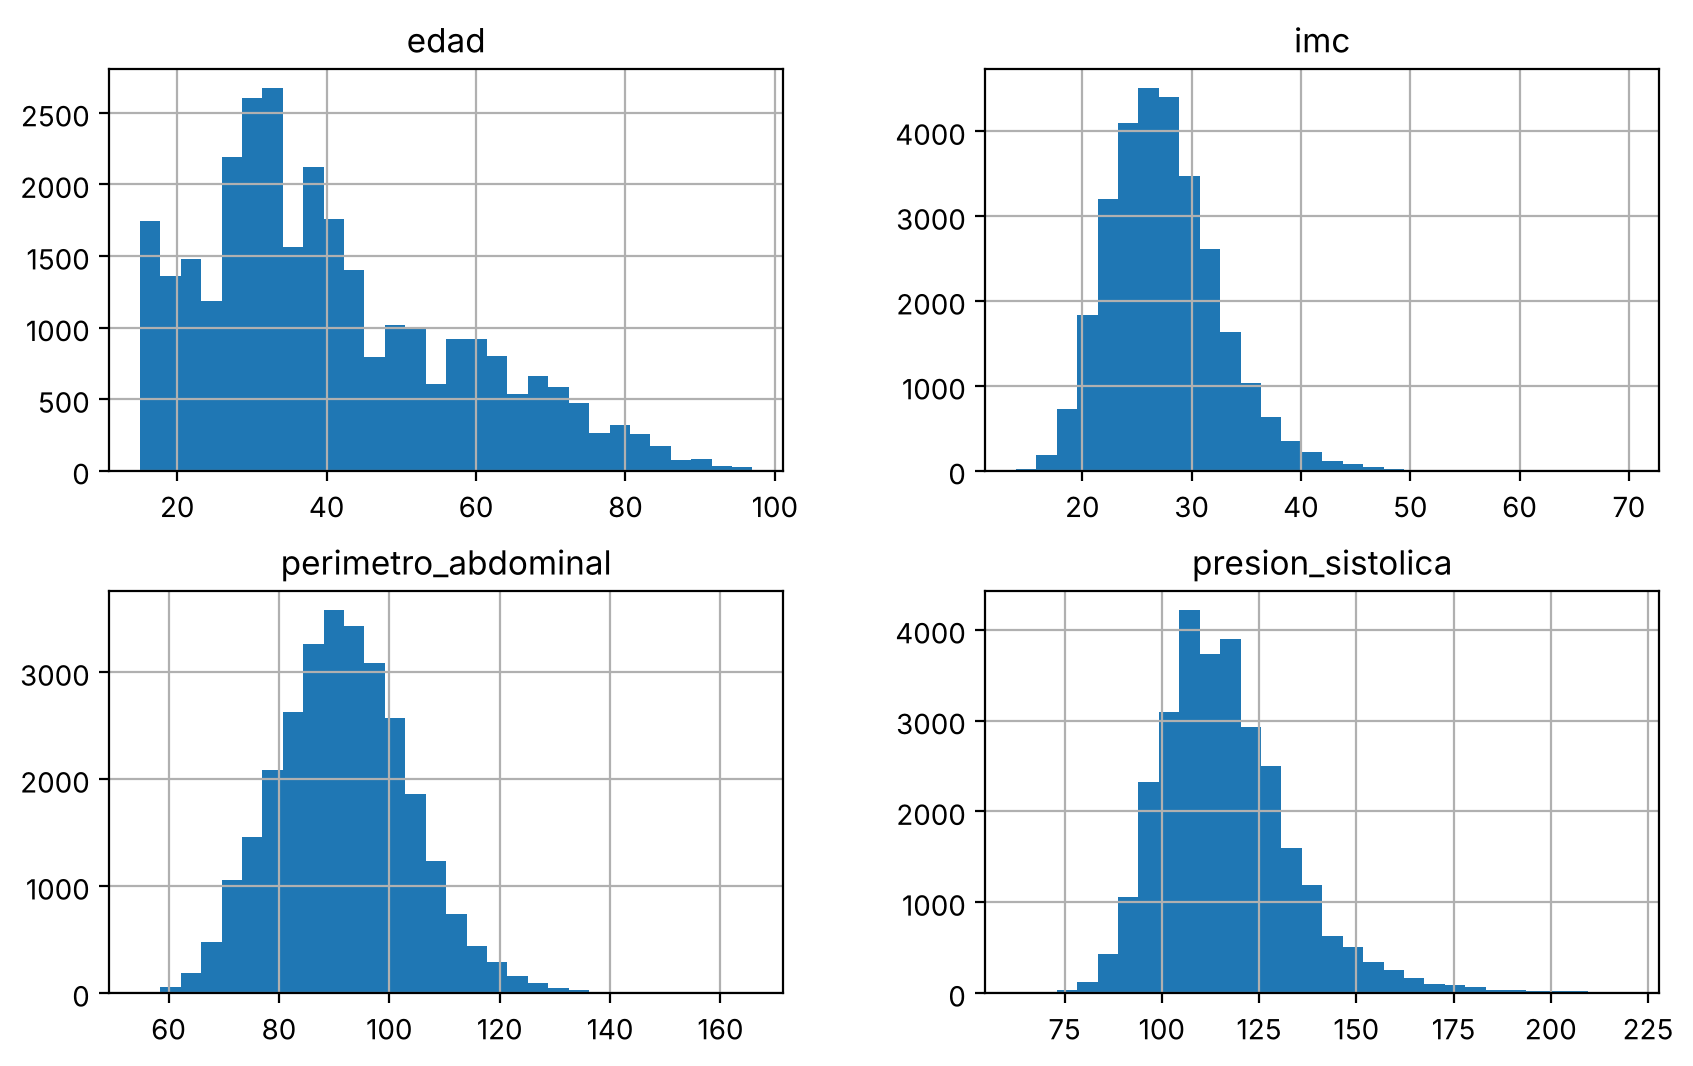

In [ ]:
# Histogramas de algunas variables numericas
X[['edad', 'imc', 'perimetro_abdominal', 'presion_sistolica']].hist(bins=30, figsize=[10, 6])
plt.show()

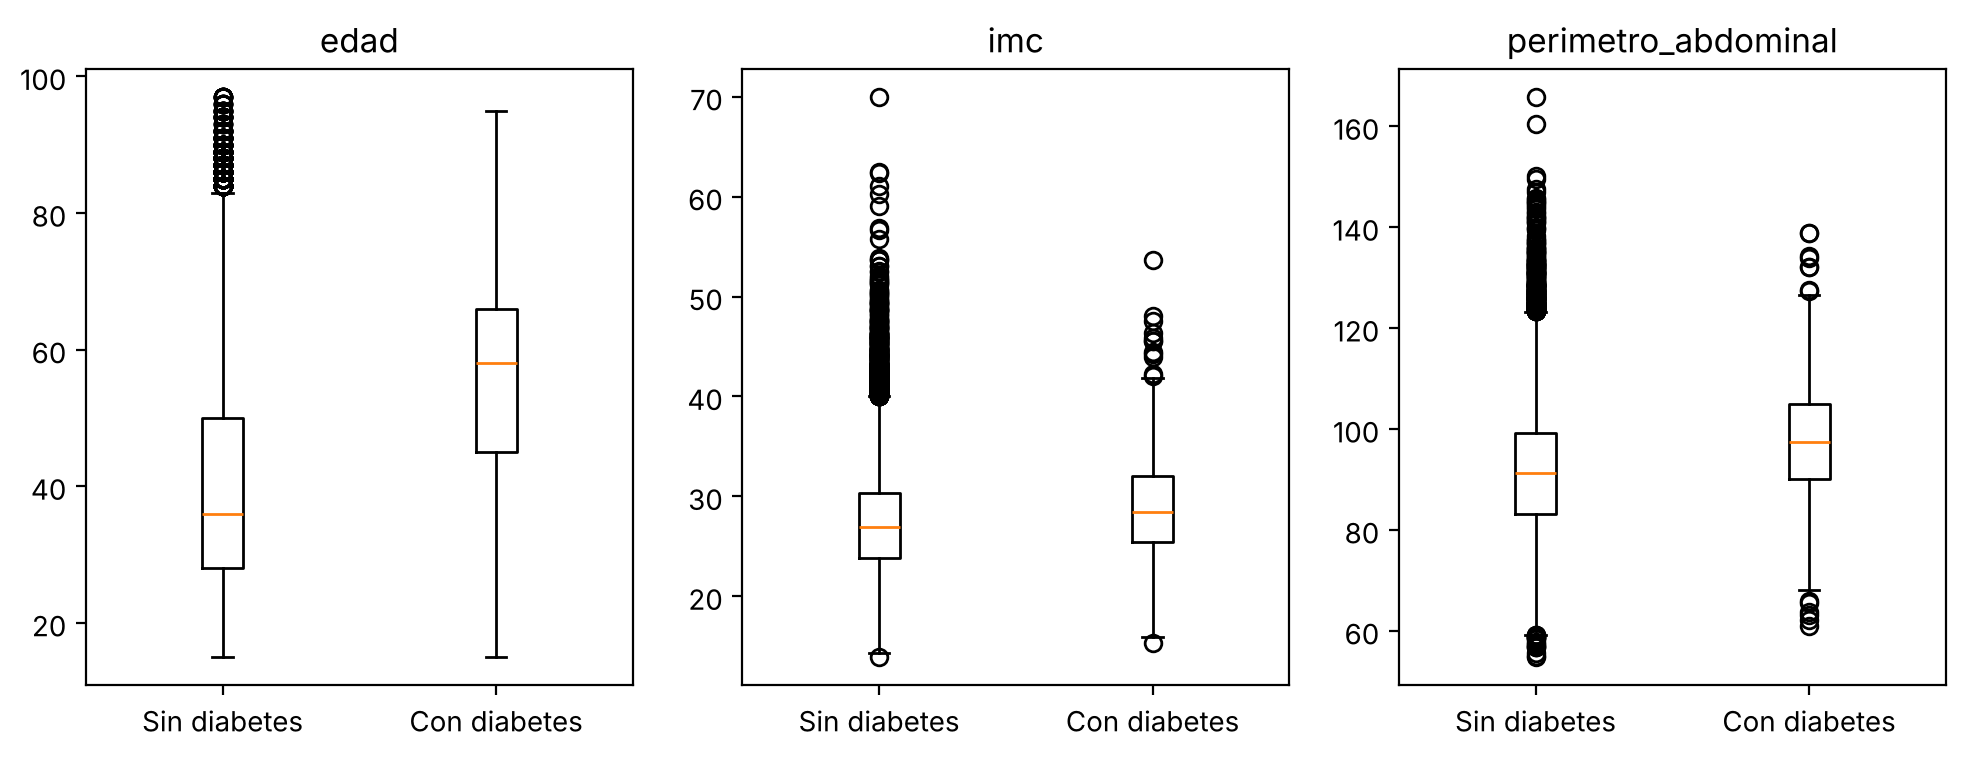

In [ ]:
# Boxplots: personas con y sin diagnostico de diabetes
fig, axs = plt.subplots(1, 3, figsize=[12, 4])
for ax, columna in zip(axs, ['edad', 'imc', 'perimetro_abdominal']):
    sin_diabetes = X.loc[salud['diabetes'] == 0, columna].dropna()
    con_diabetes = X.loc[salud['diabetes'] == 1, columna].dropna()
    ax.boxplot([sin_diabetes, con_diabetes])
    ax.set_xticklabels(['Sin diabetes', 'Con diabetes'])
    ax.set_title(columna)
plt.show()

Con la función `es_outlier` del taller (rango intercuartílico) se marcan como atípicas muchas personas con valores reales, como un IMC alto. Esas personas son justamente las más relevantes para la diabetes, por lo que **no se eliminan**.

In [ ]:
def es_outlier(df, columna, umbral=1.5):   # funcion del taller de preprocesamiento
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    return (df[columna] < q1 - umbral * iqr) | (df[columna] > q3 + umbral * iqr)


for columna in ['imc', 'perimetro_abdominal', 'presion_sistolica']:
    print('{}: {} outliers por IQR'.format(columna, es_outlier(X, columna).sum()))

imc: 497 outliers por IQR
perimetro_abdominal: 285 outliers por IQR
presion_sistolica: 786 outliers por IQR


## **Tratamiento de valores perdidos**

Porcentaje de vacíos en cada variable:

In [ ]:
(100 * X.isnull().mean()).round(2).sort_values(ascending=False).head(8)

perimetro_abdominal    2.66
talla_cm               1.32
imc                    1.32
peso_kg                1.29
presion_diastolica     0.66
presion_sistolica      0.66
nivel_educativo        0.00
seguro_salud           0.00
dtype: float64

Solo quedan vacíos en las medidas físicas (como máximo 2.7%, perímetro abdominal): son personas a las que no se pudo medir.

*   **No se eliminan esas filas**, porque su prevalencia de diabetes es mayor que la del resto (se verifica abajo). Eliminarlas quitaría casos de la clase escasa.
*   **Se imputan con la mediana**: estas variables tienen asimetría positiva (una cola de personas con obesidad o presión alta). Como pide el taller de preprocesamiento, se usa una medida de tendencia central que cambie la distribución lo menos posible, y la mediana no se deja arrastrar por esa cola.
*   **La imputación se hace dentro del pipeline**, no aquí.  *"No se debe hacer la transformacion en todo el conjunto de datos disponible y luego aplicar la estrategia de crosvalidacion para evaluar modelos porque se incurre en 'data leakage' y las metricas de evaluacion seran mejores de lo real."* La mediana se calcula solo con los datos de entrenamiento. Lo mismo pasa con el escalamiento.

In [ ]:
# Asimetria (skew > 0: cola hacia valores altos)
print(X[['peso_kg', 'talla_cm', 'imc', 'perimetro_abdominal', 'presion_sistolica', 'presion_diastolica']].skew().round(2))

peso_kg                0.78
talla_cm               0.21
imc                    0.77
perimetro_abdominal    0.30
presion_sistolica      1.08
presion_diastolica     0.52
dtype: float64


In [ ]:
fila_con_vacio = X.isnull().any(axis=1)
prevalencia_con_vacio = 100 * salud.loc[fila_con_vacio, 'diabetes'].mean()
prevalencia_sin_vacio = 100 * salud.loc[~fila_con_vacio, 'diabetes'].mean()
print('Personas con alguna medida faltante: {}'.format(fila_con_vacio.sum()))
print('Prevalencia de diabetes: {:.2f}% (con faltantes) vs {:.2f}% (resto)'.format(prevalencia_con_vacio,
                                                                                 prevalencia_sin_vacio))

Personas con alguna medida faltante: 793
Prevalencia de diabetes: 4.54% (con faltantes) vs 3.78% (resto)


## **Guardar el dataset limpio**

El dataset limpio ya no tiene códigos especiales ni blancos mal interpretados, y cada variable está en el formato que necesitan los modelos. Se agregan tres columnas auxiliares que **no** son predictores: el hogar, el factor de expansión y el departamento.

In [ ]:
datos = X.copy()
datos['HHID'] = salud['HHID']
datos['peso_muestral'] = salud['PESO15_AMAS']
datos['region_departamento'] = salud['HV024']
datos['diabetes'] = salud['diabetes']
datos.to_csv(ARCHIVO_LIMPIO, index=False)
print('El dataset limpio tiene la forma {}.'.format(datos.shape))

reporte['predictores'] = list(X.columns)
reporte['faltantes_por_variable_%'] = {c: round(100 * X[c].isnull().mean(), 2) for c in X.columns}
with open(CARPETA_RESULTADOS + 'reporte_limpieza.json', 'w', encoding='utf-8') as f:
    json.dump(reporte, f, ensure_ascii=False, indent=2)

El dataset limpio tiene la forma (29598, 26).


# **PARTE 2. PREPARACIÓN DEL EXPERIMENTO**

### Lectura del dataset limpio

Se separan los atributos (X) y el target (y). Las columnas auxiliares no se usan como predictores.

In [ ]:
df = pd.read_csv(ARCHIVO_LIMPIO)
nombres = [c for c in df.columns if c not in ['HHID', 'peso_muestral', 'region_departamento', 'diabetes']]
X = df[nombres].values      # 22 predictores
y = df['diabetes'].values   # target
print('El dataset tiene {} personas y {} predictores.'.format(X.shape[0], X.shape[1]))

El dataset tiene 29598 personas y 22 predictores.


### Partición train/test

Partición estratificada 80/20: la proporción de casos con diabetes se mantiene en ambos conjuntos. El conjunto de prueba **no se usa para ninguna decisión** (balanceo, β, λ ni selección de variables): solo se evalúa al final.

In [ ]:
indices = np.arange(len(df))
indices_train, indices_test = train_test_split(indices, test_size=0.2, stratify=y, random_state=SEMILLA)
X_train, y_train = X[indices_train], y[indices_train]
X_test, y_test = X[indices_test], y[indices_test]

print('Training: %d ejemplos (%d con diabetes). Test: %d ejemplos (%d con diabetes)' %
      (len(y_train), y_train.sum(), len(y_test), y_test.sum()))

Training: 23678 ejemplos (901 con diabetes). Test: 5920 ejemplos (225 con diabetes)


### Validación cruzada

Validación cruzada estratificada de 5 folds. Se usa **el mismo particionamiento de folds** para todos los modelos y para ABC, para que la comparación sea justa.

In [ ]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

### Clasificadores y pipelines

El preprocesamiento debe hacerse **dentro** de la validación cruzada para no incurrir en *data leakage*. Cada pipeline tiene 4 pasos:

1.  Imputar vacíos con la mediana.
2.  Estandarizar.
3.  Balancear las clases (solo afecta a los datos de entrenamiento).
4.  Clasificar.

Se usa el `Pipeline` de `imblearn`, que permite incluir el paso de balanceo.

In [ ]:
def crear_pipeline(clasificador, balanceo):
    # Paso 4: crea un clasificador nuevo (sin entrenar)
    if clasificador == 'KNN':
        modelo = KNeighborsClassifier(n_neighbors=25, weights='distance')
    elif clasificador == 'Arbol':
        modelo = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEMILLA)
    else:
        modelo = LogisticRegression(max_iter=2000)
    if balanceo == 'pesos':
        modelo.set_params(class_weight='balanced')   # pesos por clase: no cambia los datos

    # Pasos 1 y 2
    pasos = [('imputar', SimpleImputer(strategy='median')),
             ('escalar', StandardScaler())]
    # Paso 3
    if balanceo == 'submuestreo':
        pasos.append(('balancear', RandomUnderSampler(random_state=SEMILLA)))
    if balanceo == 'smote':
        pasos.append(('balancear', SMOTE(random_state=SEMILLA)))
    pasos.append(('clasificar', modelo))
    return Pipeline(pasos)


CLASIFICADORES = ['KNN', 'Arbol', 'RegLog']

### Métricas

No se usa la exactitud. Se usan recall, precisión, F1 y F2 (F-beta con β = 2, que da más peso al recall).

In [ ]:
metricas = {'recall': 'recall',
            'precision': 'precision',
            'f1': 'f1',
            'f2': make_scorer(fbeta_score, beta=2)}


def evaluar_cv(pipeline, X, y):
    # evalua el pipeline en 5-fold-CV y devuelve la media y desviacion de cada metrica
    r = cross_validate(pipeline, X, y, cv=kfold, scoring=metricas)
    resultado = {}
    for m in metricas:
        resultado[m] = r['test_' + m].mean()
        resultado[m + '_std'] = r['test_' + m].std()
    return resultado


def evaluar_test(pipeline, X_train, y_train, X_test, y_test):
    # entrena con todo el train y evalua una sola vez en test (umbral de decision 0.5)
    pipeline.fit(X_train, y_train)
    probabilidad = pipeline.predict_proba(X_test)[:, 1]
    prediccion = (probabilidad >= 0.5).astype(int)
    resultado = {'recall': recall_score(y_test, prediccion),
                 'precision': precision_score(y_test, prediccion, zero_division=0),
                 'f1': f1_score(y_test, prediccion),
                 'f2': fbeta_score(y_test, prediccion, beta=2),
                 'pr_auc': average_precision_score(y_test, probabilidad),
                 'cm': confusion_matrix(y_test, prediccion).tolist()}
    return resultado, prediccion

# **PARTE 3. ELECCIÓN DEL BALANCEO (E1)**

Se comparan las dos estrategias de balanceo vistas en el curso, **submuestreo** y **sobremuestreo** (mediante SMOTE), y como referencia los **pesos por clase**. KNN no admite pesos por clase. Para cada clasificador se elige la técnica con mayor **F2** en validación cruzada, usando las 22 variables.

In [ ]:
BALANCEOS = {'KNN': ['submuestreo', 'smote'],
             'Arbol': ['pesos', 'submuestreo', 'smote'],
             'RegLog': ['pesos', 'submuestreo', 'smote']}

filas = []
mejor_balanceo = {}
for clasificador in CLASIFICADORES:
    mejor_f2 = -1
    for balanceo in BALANCEOS[clasificador]:
        r = evaluar_cv(crear_pipeline(clasificador, balanceo), X_train, y_train)
        print('{} + {}: F2 = {:.4f} ({:.4f})'.format(clasificador, balanceo, r['f2'], r['f2_std']))
        filas.append({'clasificador': clasificador, 'balanceo': balanceo, 'recall': r['recall'],
                      'precision': r['precision'], 'f1': r['f1'], 'f2': r['f2']})
        if r['f2'] > mejor_f2:                        # nos quedamos con el de mayor F2
            mejor_f2 = r['f2']
            mejor_balanceo[clasificador] = balanceo

tabla_balanceo = pd.DataFrame(filas).round(4)
tabla_balanceo.to_csv(CARPETA_RESULTADOS + 'tabla_balanceo.csv', index=False)
print('Balanceo elegido:', mejor_balanceo)

KNN + submuestreo: F2 = 0.2835 (0.0128)


KNN + smote: F2 = 0.2438 (0.0137)


Arbol + pesos: F2 = 0.2908 (0.0143)
Arbol + submuestreo: F2 = 0.2940 (0.0140)


Arbol + smote: F2 = 0.2871 (0.0171)


RegLog + pesos: F2 = 0.3160 (0.0109)
RegLog + submuestreo: F2 = 0.3120 (0.0133)


RegLog + smote: F2 = 0.3168 (0.0095)
Balanceo elegido: {'KNN': 'submuestreo', 'Arbol': 'submuestreo', 'RegLog': 'smote'}


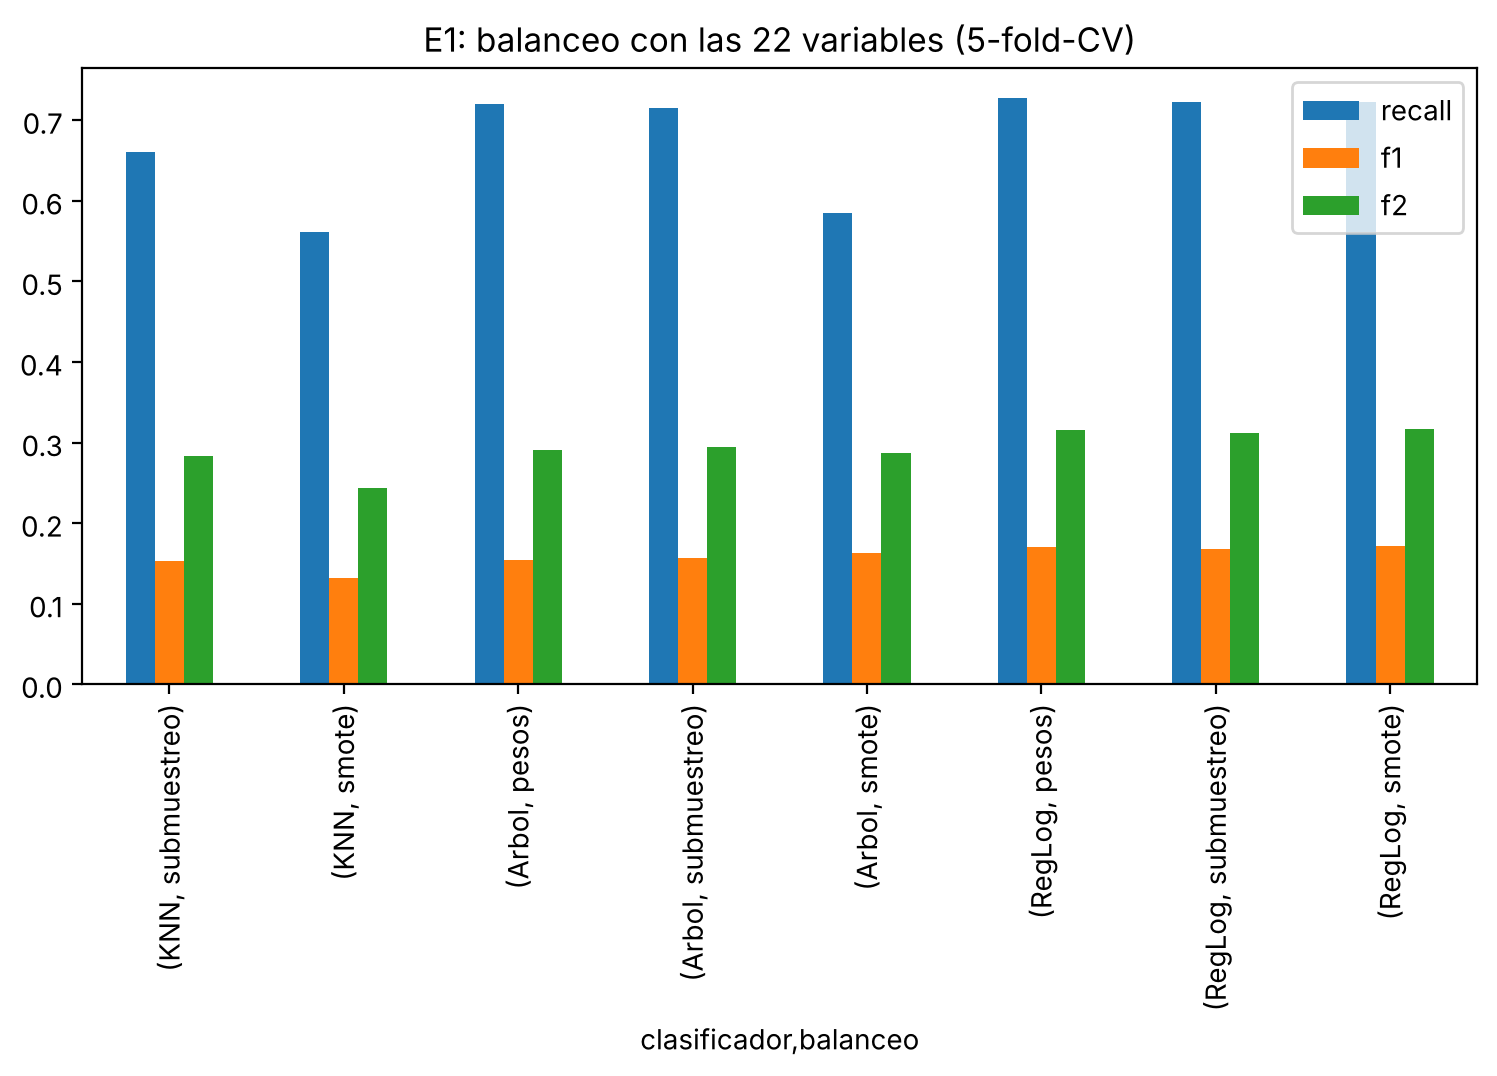

In [ ]:
# Grafico de recall, F1 y F2 de cada combinacion
tabla_balanceo.set_index(['clasificador', 'balanceo'])[['recall', 'f1', 'f2']].plot.bar(figsize=[9, 4])
plt.title('E1: balanceo con las 22 variables (5-fold-CV)')
plt.show()

# **PARTE 4. ALGORITMO ABC BINARIO**

Los cambios para un espacio binario están marcados con **ADAPTACIÓN** en el código:

1.  **Solución = máscara binaria** z de 22 posiciones: z_j = 1 si la variable j se usa.
2.  **Función a minimizar**: fn(z) = 1 − F(z), con **F(z) = F_β(z) − λ·|S(z)|/22**. Así el fitness del taller, 1/(1 + fn), queda igual.
3.  **Solución vecina**: en vez de Xi + r·(Xi − Xk), que es para valores continuos, se **invierten bits**. La otra fuente Xk se elige con probabilidad proporcional a su **distancia de Hamming** (número de posiciones en que difieren).
4.  **Bits invertidos**: bajan de 6 (⌈22/4⌉) a 1 a lo largo de los ciclos: exploración amplia al inicio, ajuste fino al final.
5.  **Memoria de máscaras evaluadas**, para no repetir la validación cruzada de una máscara ya vista.

### Clase FoodSource (igual que en el taller)

In [ ]:
class FoodSource(object):
    """Almacena una fuente de comida: una mascara binaria, su fitness y sus intentos sin mejora"""

    def __init__(self, solution, fitness):
        self.solution = solution
        self.fitness = fitness
        self.trials = 0

### Generador de fuentes de comida binarias

In [ ]:
class ABC_foodsources:
    """ Genera las fuentes de comida iniciales. Recibe:
        SN: numero de fuentes de comida
        d: numero de variables (largo de la mascara)
        seed: semilla del generador aleatorio """

    def __init__(self, SN, d, seed=0):
        self.SN = SN
        self.d = d
        self.rng = np.random.default_rng(seed)   # generador aleatorio que tambien usara ABC
        self.values = self.initialize_foodsources()

    def get_randomsolution(self):
        # ADAPTACION: cada variable se incluye con probabilidad 0.5 (en el taller: un punto entre coord_min y coord_max)
        solution = (self.rng.random(self.d) < 0.5).astype(np.int8)
        if solution.sum() == 0:                       # una mascara vacia no sirve: se activa una variable
            solution[self.rng.integers(self.d)] = 1
        return solution

    def create_foodsource(self):
        return self.get_randomsolution()

    def initialize_foodsources(self):
        return [self.create_foodsource() for _ in range(self.SN)]

### Función objetivo: fn(z) = 1 − F(z)

Para una máscara z se entrena un árbol de decisión solo con las variables marcadas con 1 y se evalúa en la validación cruzada de 5 folds:

*   **F(z) = F_β − λ·(número de variables)/22**, con la formulación final.
*   **F(z) = α·Recall + (1 − α)·F1 − λ·(número de variables)/22**, con la formulación inicial del entregable parcial (experimento E0), usando `beta=None`.

ABC minimiza fn(z) = 1 − F(z). La memoria guarda cada máscara ya evaluada.

In [ ]:
class FuncionObjetivo:
    def __init__(self, X, y, estimador, cv, beta=2.0, lam=0.1, alpha=None):
        self.X = X
        self.y = y
        self.d = X.shape[1]          # numero total de variables (22)
        self.estimador = estimador   # clasificador con el que se evalua cada mascara
        self.cv = cv
        self.beta = beta
        self.lam = lam
        self.alpha = alpha
        self.memoria = {}            # mascara -> (F, recall, f1)

    def evaluar(self, solution):
        clave = tuple(solution)                       # la mascara como clave del diccionario
        if clave not in self.memoria:                 # solo se evalua si es nueva
            columnas = np.flatnonzero(solution)       # posiciones de las variables seleccionadas
            scoring = {'recall': 'recall', 'f1': 'f1'}
            if self.beta is not None:
                scoring['fb'] = make_scorer(fbeta_score, beta=self.beta)
            r = cross_validate(self.estimador, self.X[:, columnas], self.y, cv=self.cv, scoring=scoring)
            recall = r['test_recall'].mean()
            f1 = r['test_f1'].mean()
            penalizacion = self.lam * len(columnas) / self.d
            if self.beta is not None:
                F = r['test_fb'].mean() - penalizacion
            else:
                F = self.alpha * recall + (1 - self.alpha) * f1 - penalizacion
            self.memoria[clave] = (F, recall, f1)
        return self.memoria[clave]

    def __call__(self, solution):
        F = self.evaluar(solution)[0]
        return 1.0 - F                                # valor que ABC minimiza

### Clase ABC binario

In [ ]:
class ABC:
    """ Optimizador ABC binario. Recibe:
        fn: la funcion a ser minimizada
        foodsources: fuentes de comida iniciales
        limit: ciclos que se conserva una fuente sin mejorar antes de abandonarla
        max_iter: numero de ciclos """

    def __init__(self, fn, foodsources, limit, max_iter, verbose=True):
        self.fn = fn
        self.SN = foodsources.SN
        self.d = foodsources.d
        self.rng = foodsources.rng
        self.limit = limit
        self.max_iter = max_iter
        self.max_bits = max(2, int(np.ceil(self.d / 4)))   # bits a invertir en el primer ciclo (6)
        self.verbose = verbose
        self.foodsources = [FoodSource(s, self.fitness(s)) for s in foodsources.values]
        self.fn_create_foodsource = foodsources.create_foodsource

    def fitness(self, solution):
        # igual que en el taller: fn >= 0 se lleva a [0,1]
        result = self.fn(solution)
        if result >= 0:
            return 1 / (1 + result)
        else:
            return 1 + abs(result)

    def bits_a_invertir(self, ciclo):
        # ADAPTACION: baja linealmente de max_bits (primer ciclo) a 1 (ultimo ciclo)
        avance = ciclo / max(1, self.max_iter - 1)
        return max(1, int(round(self.max_bits - avance * (self.max_bits - 1))))

    def produce_neighboursolution(self, i, ciclo):
        Xi = self.foodsources[i].solution
        otras = [k for k in range(self.SN) if k != i]
        # ADAPTACION: Xk se elige con probabilidad proporcional a su distancia de Hamming con Xi
        distancias = np.array([np.sum(Xi != self.foodsources[k].solution) for k in otras], dtype=float)
        if distancias.sum() > 0:
            k = otras[self.rng.choice(len(otras), p=distancias / distancias.sum())]
            posiciones = np.flatnonzero(Xi != self.foodsources[k].solution)   # donde Xi y Xk difieren
        else:
            posiciones = np.arange(self.d)            # todas las fuentes son iguales
        # ADAPTACION: se invierten algunos bits en esas posiciones (en el taller: Xi + r*(Xi - Xk))
        m = min(self.bits_a_invertir(ciclo), len(posiciones))
        elegidas = self.rng.choice(posiciones, size=m, replace=False)
        Vi = Xi.copy()
        Vi[elegidas] = 1 - Vi[elegidas]               # 0 -> 1 y 1 -> 0
        if Vi.sum() == 0:                             # evita la mascara vacia
            Vi[self.rng.integers(self.d)] = 1
        return Vi

    def get_bestsolution(self, foodsource, V):
        # devuelve la mejor solucion entre la actual y la candidata V
        if self.fitness(V) > foodsource.fitness:
            return V
        else:
            return foodsource.solution

    def get_probs_foodsources(self):
        fitness = np.array([fs.fitness for fs in self.foodsources])
        return fitness / fitness.sum()

    def update_solution_foodsource(self, foodsource, new_solution):
        if np.array_equal(new_solution, foodsource.solution):   # no mejoro: suma un intento
            foodsource.trials += 1
        else:                                                    # mejoro: se reemplaza
            foodsource.solution = new_solution
            foodsource.fitness = self.fitness(new_solution)
            foodsource.trials = 0

    def selection(self, probabilities):
        return int(self.rng.choice(self.SN, p=probabilities))   # ruleta

    def get_bestfoodsource(self):
        return max(self.foodsources, key=attrgetter('fitness'))

    def create_new_foodsource(self):
        solution = self.fn_create_foodsource()
        return FoodSource(solution, self.fitness(solution))

    def optimize(self):
        start_time = time.time()
        best = self.get_bestfoodsource()
        best_solution, best_fitness = deepcopy(best.solution), best.fitness
        history_bestF = []          # mejor F(z) encontrado hasta cada ciclo

        for g in range(self.max_iter):
            ## Abejas empleadas
            for i in range(self.SN):
                Vi = self.produce_neighboursolution(i, g)
                solution = self.get_bestsolution(self.foodsources[i], Vi)
                self.update_solution_foodsource(self.foodsources[i], solution)

            ## Abejas observadoras (probabilidades calculadas al inicio de la fase)
            probabilities = self.get_probs_foodsources()
            for i in range(self.SN):
                j = self.selection(probabilities)
                Vj = self.produce_neighboursolution(j, g)
                solution = self.get_bestsolution(self.foodsources[j], Vj)
                self.update_solution_foodsource(self.foodsources[j], solution)

            ## Abejas exploradoras (version V1 del taller: abandona todas las que superan el limite)
            for i in range(self.SN):
                if self.foodsources[i].trials > self.limit:
                    self.foodsources[i] = self.create_new_foodsource()

            ## Memoriza la mejor solucion encontrada hasta ahora
            best = self.get_bestfoodsource()
            if best.fitness > best_fitness:
                best_solution, best_fitness = deepcopy(best.solution), best.fitness
            # ADAPTACION: se guarda la mejor historica, por eso la curva de convergencia es monotona
            history_bestF.append(self.fn.evaluar(best_solution)[0])

            if self.verbose and g % 5 == 0:
                print('Ciclo {}: {} variables, F = {:.4f}'.format(g, best_solution.sum(), history_bestF[-1]))

        self.tiempo_s = time.time() - start_time
        return best_solution, best_fitness, history_bestF

### Clasificador con el que ABC evalúa cada máscara

Un árbol de decisión de profundidad 5 con pesos por clase. Se usan pesos por clase (y no SMOTE) porque ABC evalúa cientos de máscaras, y generar casos sintéticos en cada evaluación multiplicaría el tiempo.

In [ ]:
arbol_abc = Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('clasificar', DecisionTreeClassifier(max_depth=5, class_weight='balanced',
                                                            random_state=SEMILLA))])

### Función para ejecutar ABC completo

Junta los tres pasos del taller (fuentes iniciales, optimizador y `optimize`) y devuelve la máscara encontrada con sus métricas.

In [ ]:
def ejecutar_abc(beta, lam, semilla, alpha=None, verbose=False):
    fn = FuncionObjetivo(X_train, y_train, arbol_abc, kfold, beta=beta, lam=lam, alpha=alpha)
    fuentes = ABC_foodsources(SN, fn.d, seed=semilla)               # fuentes de comida iniciales
    optimizador = ABC(fn, fuentes, LIMITE, MAX_ITER, verbose=verbose)
    mascara, fitness, historial = optimizador.optimize()
    F, recall, f1 = fn.evaluar(mascara)
    return {'mascara': mascara, 'F': F, 'recall_cv': recall, 'f1_cv': f1, 'historial': historial,
            'evaluaciones': len(fn.memoria), 'tiempo_s': optimizador.tiempo_s}


def variables_de(mascara):
    # nombres de las variables seleccionadas por una mascara
    return [nombres[j] for j in np.flatnonzero(mascara)]

### Probando el algoritmo ABC (β = 2, λ = 0.1, semilla 0)

In [ ]:
prueba = ejecutar_abc(BETA, LAMBDA, semilla=0, verbose=True)
print('Variables seleccionadas:', variables_de(prueba['mascara']))
print('Tiempo: {:.1f} segundos, mascaras evaluadas: {}'.format(prueba['tiempo_s'], prueba['evaluaciones']))

Ciclo 0: 9 variables, F = 0.2613


Ciclo 5: 7 variables, F = 0.2751


Ciclo 10: 6 variables, F = 0.2781


Ciclo 15: 5 variables, F = 0.2900


Ciclo 20: 6 variables, F = 0.2901


Ciclo 25: 5 variables, F = 0.2954


Variables seleccionadas: ['edad', 'perimetro_abdominal', 'presion_sistolica', 'alcohol_30d', 'quintil_riqueza']
Tiempo: 66.2 segundos, mascaras evaluadas: 426


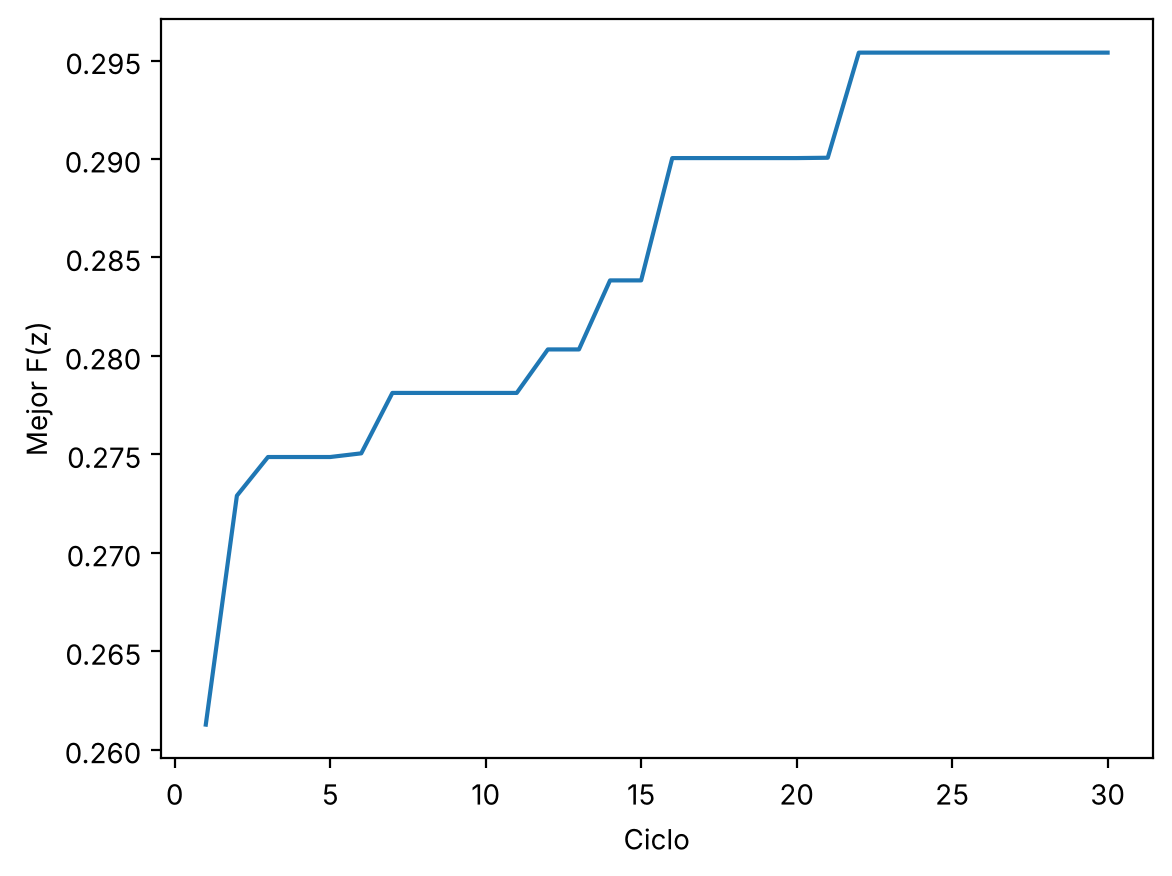

In [ ]:
# Evolucion del mejor F(z) encontrado
plt.plot(range(1, len(prueba['historial']) + 1), prueba['historial'])
plt.xlabel('Ciclo'); plt.ylabel('Mejor F(z)')
plt.show()

La curva nunca baja porque se grafica la **mejor solución encontrada hasta cada ciclo** (pregunta final del taller), y no la mejor de la población actual, que puede bajar cuando una abeja exploradora reemplaza una fuente.

# **PARTE 5. PARÁMETROS DE LA FUNCIÓN DE APTITUD (E0 y E2)**

### E0: formulación inicial, α·Recall + (1 − α)·F1

Es la aptitud planteada en el entregable parcial. Con menos de 4% de positivos el F1 es bajo para cualquier modelo, así que su término pesa poco, y la búsqueda puede terminar premiando máscaras que marcan a casi todos como positivos (recall alto, F1 casi nulo).

In [ ]:
if EJECUTAR_E0:
    filas = []
    for alpha in VALORES_ALPHA:
        for lam in VALORES_LAMBDA:
            r = ejecutar_abc(beta=None, lam=lam, semilla=0, alpha=alpha)
            print('alpha={}, lambda={}: {} -> recall {:.3f}, F1 {:.3f}'.format(
                alpha, lam, variables_de(r['mascara']), r['recall_cv'], r['f1_cv']))
            filas.append({'alpha': alpha, 'lambda': lam, 'n_variables': int(r['mascara'].sum()),
                          'recall_cv': r['recall_cv'], 'f1_cv': r['f1_cv'], 'F': r['F'],
                          'evaluaciones': r['evaluaciones'], 'tiempo_s': r['tiempo_s'],
                          'variables': ', '.join(variables_de(r['mascara']))})
    tabla_e0 = pd.DataFrame(filas).round(4)
    tabla_e0.to_csv(CARPETA_RESULTADOS + 'tabla_grid_formulacion_inicial.csv', index=False)

alpha=0.6, lambda=0.05: ['edad', 'peso_kg', 'talla_cm', 'region_sierra'] -> recall 0.746, F1 0.149


alpha=0.6, lambda=0.1: ['edad', 'talla_cm', 'imc', 'alcohol_30d'] -> recall 0.760, F1 0.145


alpha=0.6, lambda=0.2: ['edad'] -> recall 0.735, F1 0.157


alpha=0.7, lambda=0.05: ['edad', 'peso_kg', 'talla_cm', 'alcohol_12dias_12m'] -> recall 0.746, F1 0.146


alpha=0.7, lambda=0.1: ['edad', 'talla_cm', 'imc'] -> recall 0.749, F1 0.144


alpha=0.7, lambda=0.2: ['edad', 'mujer'] -> recall 0.754, F1 0.153


alpha=0.8, lambda=0.05: ['edad', 'seguro_salud', 'talla_cm', 'imc', 'area_rural', 'quintil_riqueza', 'region_sierra'] -> recall 0.755, F1 0.152


alpha=0.8, lambda=0.1: ['edad', 'seguro_salud', 'talla_cm', 'imc', 'quintil_riqueza', 'region_sierra'] -> recall 0.751, F1 0.151


alpha=0.8, lambda=0.2: ['fumo_12m', 'fumo_30d'] -> recall 0.897, F1 0.077


### E2: formulación final, F_β − λ·|S|/22

Se prueban 3 valores de β y 3 de λ con la semilla 0. La combinación β = 2, λ = 0.1 ya se ejecutó en la prueba anterior.

In [ ]:
filas = []
for beta in VALORES_BETA:
    for lam in VALORES_LAMBDA:
        if beta == BETA and lam == LAMBDA:
            r = prueba                                   # ya se ejecuto arriba
        else:
            r = ejecutar_abc(beta, lam, semilla=0)
        print('beta={}, lambda={}: {} -> recall {:.3f}, F1 {:.3f}'.format(
            beta, lam, variables_de(r['mascara']), r['recall_cv'], r['f1_cv']))
        filas.append({'beta': beta, 'lambda': lam, 'n_variables': int(r['mascara'].sum()),
                      'recall_cv': r['recall_cv'], 'f1_cv': r['f1_cv'], 'F': r['F'],
                      'evaluaciones': r['evaluaciones'], 'tiempo_s': r['tiempo_s'],
                      'variables': ', '.join(variables_de(r['mascara']))})
tabla_grid = pd.DataFrame(filas).round(4)
tabla_grid.to_csv(CARPETA_RESULTADOS + 'tabla_grid_beta_lambda.csv', index=False)

beta=1.0, lambda=0.05: ['edad', 'perimetro_abdominal', 'presion_sistolica', 'quintil_riqueza', 'region_resto_costa'] -> recall 0.685, F1 0.173


beta=1.0, lambda=0.1: ['edad', 'alcohol_12m', 'quintil_riqueza'] -> recall 0.690, F1 0.174


beta=1.0, lambda=0.2: ['edad'] -> recall 0.735, F1 0.157


beta=2.0, lambda=0.05: ['edad', 'mujer', 'seguro_salud', 'presion_sistolica', 'alcohol_12dias_12m', 'alcohol_30d', 'quintil_riqueza'] -> recall 0.683, F1 0.178
beta=2.0, lambda=0.1: ['edad', 'perimetro_abdominal', 'presion_sistolica', 'alcohol_30d', 'quintil_riqueza'] -> recall 0.686, F1 0.177


beta=2.0, lambda=0.2: ['edad', 'mujer', 'quintil_riqueza'] -> recall 0.705, F1 0.167


beta=3.0, lambda=0.05: ['edad', 'mujer', 'seguro_salud', 'presion_sistolica', 'alcohol_30d', 'quintil_riqueza'] -> recall 0.685, F1 0.178


beta=3.0, lambda=0.1: ['edad', 'quintil_riqueza', 'region_resto_costa'] -> recall 0.713, F1 0.167


beta=3.0, lambda=0.2: ['edad'] -> recall 0.735, F1 0.157


# **PARTE 6. COMPARACIÓN ABC vs. SelectKBest vs. TODAS LAS VARIABLES (E3)**

### ABC con 5 semillas

ABC es aleatorio, así que se ejecuta con 5 semillas para ver qué tan estable es la selección.

In [ ]:
abc = {}   # resultado de ABC por semilla
for semilla in SEMILLAS_ABC:
    if semilla == 0:
        abc[semilla] = prueba                            # la semilla 0 ya se ejecuto
    else:
        abc[semilla] = ejecutar_abc(BETA, LAMBDA, semilla)
    print('Semilla {}: {} ({:.0f} segundos)'.format(semilla, variables_de(abc[semilla]['mascara']),
                                                    abc[semilla]['tiempo_s']))

historiales = {semilla: [float(v) for v in abc[semilla]['historial']] for semilla in SEMILLAS_ABC}
with open(CARPETA_RESULTADOS + 'historial_convergencia.json', 'w') as f:
    json.dump(historiales, f)

Semilla 0: ['edad', 'perimetro_abdominal', 'presion_sistolica', 'alcohol_30d', 'quintil_riqueza'] (66 segundos)


Semilla 1: ['edad', 'alcohol_12m', 'quintil_riqueza'] (66 segundos)


Semilla 2: ['edad', 'alcohol_12m', 'quintil_riqueza'] (54 segundos)


Semilla 3: ['edad', 'mujer', 'nivel_educativo', 'quintil_riqueza'] (67 segundos)


Semilla 4: ['edad', 'alcohol_12m', 'quintil_riqueza'] (72 segundos)


### SelectKBest (método de filtro)

Como en el taller de reducción dimensional, `SelectKBest` da un puntaje a cada variable por separado y se queda con las k mejores. Se usa la **información mutua** (`mutual_info_classif`), que capta relaciones no lineales y admite variables discretas. Para una comparación justa se le da **el mismo k que eligió ABC** en cada semilla. Los vacíos se imputan antes con la mediana del train.

In [ ]:
# variables discretas (binarias u ordinales), necesarias para calcular bien la informacion mutua
discretas = []
for c in nombres:
    es_discreta = c in ['mujer', 'nivel_educativo', 'seguro_salud', 'area_rural', 'quintil_riqueza'] \
        or c.startswith('fum') or c.startswith('alcohol') or c.startswith('region')
    discretas.append(es_discreta)


def informacion_mutua(X, y):
    return mutual_info_classif(X, y, discrete_features=discretas, random_state=SEMILLA)


def crear_selectkbest(k):
    return Pipeline([('imputar', SimpleImputer(strategy='median')),
                     ('seleccionar', SelectKBest(score_func=informacion_mutua, k=k))])


# Puntaje de cada variable
fit_selector = crear_selectkbest('all').fit(X_train, y_train)
puntajes = pd.DataFrame({'variable': nombres, 'score': fit_selector.named_steps['seleccionar'].scores_})
puntajes.sort_values('score', ascending=False).round(4).head(10)

,variable,score
0,edad,0.0212
7,perimetro_abdominal,0.0062
8,presion_sistolica,0.0047
6,imc,0.0029
9,presion_diastolica,0.0026
18,quintil_riqueza,0.0017
4,peso_kg,0.0015
20,region_sierra,0.0013
14,alcohol_12m,0.0012
5,talla_cm,0.0012


### Entrenamiento y evaluación de las tres condiciones

Para cada condición (todas las variables, SelectKBest y ABC) se entrenan los tres clasificadores con el balanceo elegido en E1. Se guardan los resultados en validación cruzada (train) y en el conjunto de prueba.

In [ ]:
resultados = []   # una fila por condicion, semilla y clasificador


def entrenar_y_evaluar(condicion, semilla, columnas, tiempo_seleccion):
    for clasificador in CLASIFICADORES:
        pipeline = crear_pipeline(clasificador, mejor_balanceo[clasificador])
        cv = evaluar_cv(pipeline, X_train[:, columnas], y_train)
        test, _ = evaluar_test(pipeline, X_train[:, columnas], y_train, X_test[:, columnas], y_test)
        resultados.append({'condicion': condicion, 'semilla': semilla, 'clasificador': clasificador,
                           'k': len(columnas),
                           'cv_recall': cv['recall'], 'cv_recall_std': cv['recall_std'],
                           'cv_f1': cv['f1'], 'cv_f1_std': cv['f1_std'],
                           'test_recall': test['recall'], 'test_precision': test['precision'],
                           'test_f1': test['f1'], 'test_f2': test['f2'], 'test_pr_auc': test['pr_auc'],
                           'cm': test['cm'], 'tiempo_seleccion_s': tiempo_seleccion})

In [ ]:
# Condicion 1: las 22 variables
todas = list(range(len(nombres)))
entrenar_y_evaluar('Todas', -1, todas, 0.0)

In [ ]:
# Condiciones 2 y 3: SelectKBest y ABC con el mismo k, para cada semilla
columnas_skb = {}
for semilla in SEMILLAS_ABC:
    columnas_abc = list(np.flatnonzero(abc[semilla]['mascara']))
    k = len(columnas_abc)

    inicio = time.perf_counter()
    selector = crear_selectkbest(k).fit(X_train, y_train)
    tiempo_skb = time.perf_counter() - inicio
    columnas_skb[semilla] = list(selector.named_steps['seleccionar'].get_support(indices=True))

    entrenar_y_evaluar('SelectKBest', semilla, columnas_skb[semilla], tiempo_skb)
    entrenar_y_evaluar('ABC', semilla, columnas_abc, abc[semilla]['tiempo_s'])
    print('Semilla {}, k={}'.format(semilla, k))
    print('   ABC:', [nombres[c] for c in columnas_abc])
    print('   SKB:', [nombres[c] for c in columnas_skb[semilla]])

res = pd.DataFrame(resultados)
res.to_csv(CARPETA_RESULTADOS + 'resultados_detalle.csv', index=False)

Semilla 0, k=5
   ABC: ['edad', 'perimetro_abdominal', 'presion_sistolica', 'alcohol_30d', 'quintil_riqueza']
   SKB: ['edad', 'imc', 'perimetro_abdominal', 'presion_sistolica', 'presion_diastolica']


Semilla 1, k=3
   ABC: ['edad', 'alcohol_12m', 'quintil_riqueza']
   SKB: ['edad', 'perimetro_abdominal', 'presion_sistolica']


Semilla 2, k=3
   ABC: ['edad', 'alcohol_12m', 'quintil_riqueza']
   SKB: ['edad', 'perimetro_abdominal', 'presion_sistolica']


Semilla 3, k=4
   ABC: ['edad', 'mujer', 'nivel_educativo', 'quintil_riqueza']
   SKB: ['edad', 'imc', 'perimetro_abdominal', 'presion_sistolica']


Semilla 4, k=3
   ABC: ['edad', 'alcohol_12m', 'quintil_riqueza']
   SKB: ['edad', 'perimetro_abdominal', 'presion_sistolica']


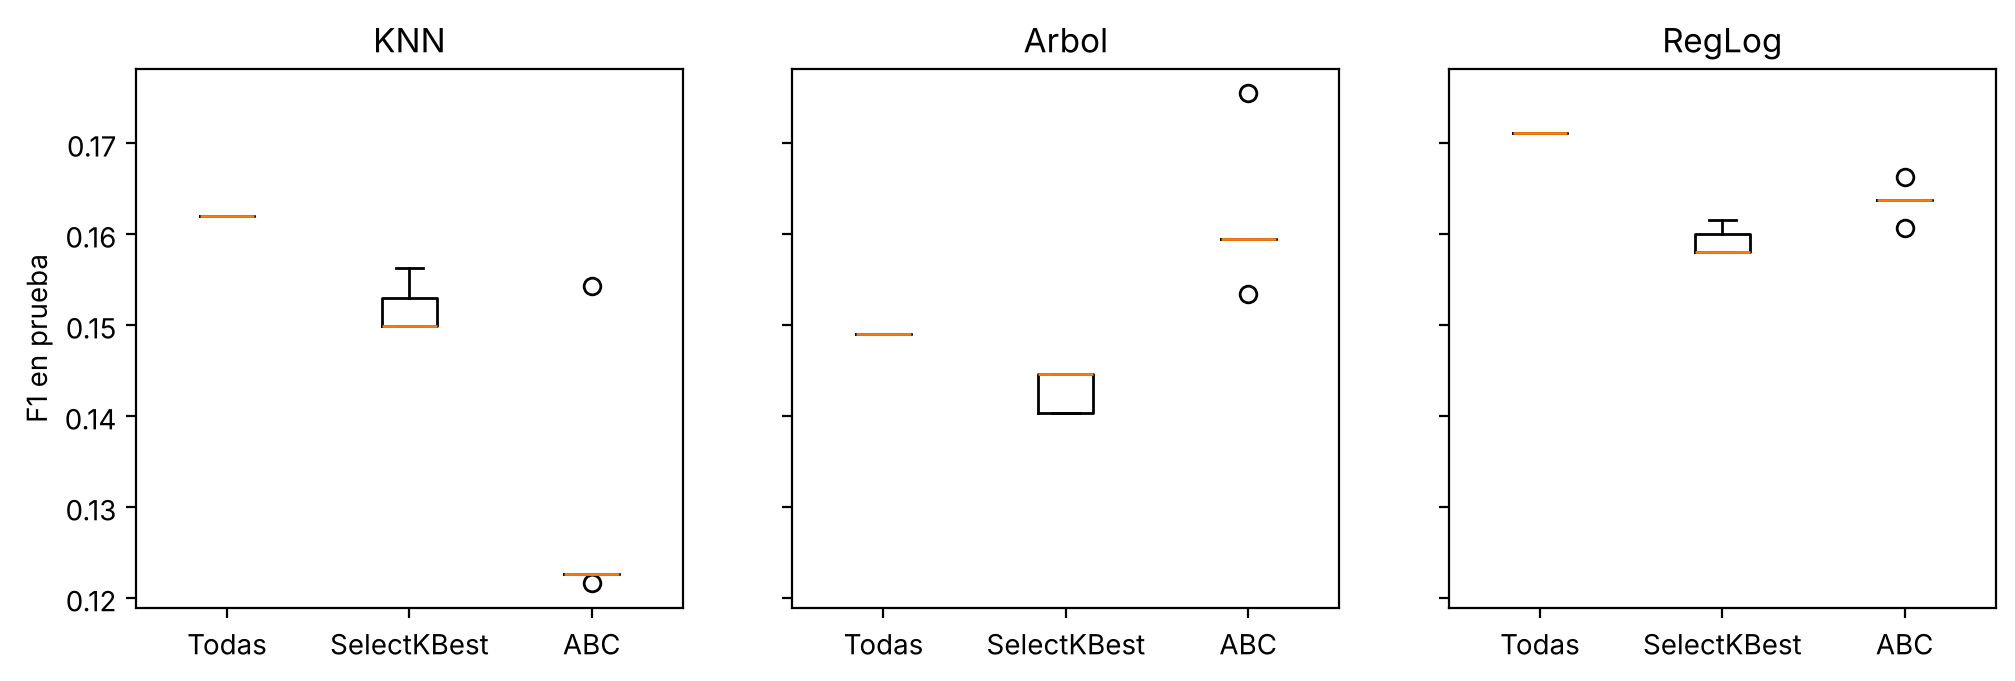

In [ ]:
# F1 en prueba de cada condicion (cada caja resume las 5 semillas)
fig, axs = plt.subplots(1, 3, figsize=[12, 3.5], sharey=True)
for ax, clasificador in zip(axs, CLASIFICADORES):
    cajas = []
    for condicion in ['Todas', 'SelectKBest', 'ABC']:
        filtro = (res['condicion'] == condicion) & (res['clasificador'] == clasificador)
        cajas.append(res.loc[filtro, 'test_f1'])
    ax.boxplot(cajas)
    ax.set_xticklabels(['Todas', 'SelectKBest', 'ABC'])
    ax.set_title(clasificador)
axs[0].set_ylabel('F1 en prueba')
plt.show()

### Tabla resumen

Media y desviación estándar de las 5 semillas para cada clasificador y condición.

In [ ]:
columnas_tabla = ['k', 'cv_recall', 'cv_f1', 'test_recall', 'test_precision', 'test_f1', 'test_f2',
                  'test_pr_auc', 'tiempo_seleccion_s']
tabla_principal = res.groupby(['clasificador', 'condicion'])[columnas_tabla].agg(['mean', 'std']).round(4)
tabla_principal.to_csv(CARPETA_RESULTADOS + 'tabla_principal.csv')

# Vista simple: solo las medias
res.groupby(['clasificador', 'condicion'])[['k', 'test_recall', 'test_f1', 'tiempo_seleccion_s']].mean().round(3)

k  test_recall  test_f1  tiempo_seleccion_s
clasificador condicion                                                  
Arbol        ABC           3.6        0.727    0.161              64.915
             SelectKBest   3.6        0.731    0.143               0.478
             Todas        22.0        0.733    0.149               0.000
KNN          ABC           3.6        0.681    0.129              64.915
             SelectKBest   3.6        0.746    0.152               0.478
             Todas        22.0        0.676    0.162               0.000
RegLog       ABC           3.6        0.704    0.164              64.915
             SelectKBest   3.6        0.710    0.159               0.478
             Todas        22.0        0.720    0.171               0.000

### ¿Hay pérdida relevante frente a las 22 variables? (hipótesis)

La reducción de variables **no** tiene pérdida relevante si la caída del recall y del F1 en validación cruzada, respecto del modelo con todas las variables, es **menor a una desviación estándar** de ese modelo.

In [ ]:
filas = []
for clasificador in CLASIFICADORES:
    base = res[(res['condicion'] == 'Todas') & (res['clasificador'] == clasificador)].iloc[0]
    con_abc = res[(res['condicion'] == 'ABC') & (res['clasificador'] == clasificador)]
    for metrica in ['recall', 'f1']:
        caida = base['cv_' + metrica] - con_abc['cv_' + metrica].mean()
        desviacion = base['cv_' + metrica + '_std']
        filas.append({'clasificador': clasificador, 'metrica': metrica, 'todas': base['cv_' + metrica],
                      'todas_std': desviacion, 'abc_media': con_abc['cv_' + metrica].mean(),
                      'caida': caida, 'perdida_relevante': bool(caida > desviacion)})
tabla_perdida = pd.DataFrame(filas).round(4)
tabla_perdida.to_csv(CARPETA_RESULTADOS + 'tabla_perdida_relevante.csv', index=False)
tabla_perdida

,clasificador,metrica,todas,todas_std,abc_media,caida,perdida_relevante
0,KNN,recall,0.6604,0.0413,0.6310,0.0293,False
1,KNN,f1,0.1528,0.0062,0.1390,0.0137,True
2,Arbol,recall,0.7148,0.0356,0.6986,0.0162,False
3,Arbol,f1,0.1563,0.0086,0.1680,-0.0117,False
4,RegLog,recall,0.7225,0.0214,0.7103,0.0122,False
5,RegLog,f1,0.1720,0.0053,0.1640,0.0080,True


### ¿ABC es igual o mejor que SelectKBest? (hipótesis)

Comparación con la misma semilla y el mismo k.

In [ ]:
filas = []
for clasificador in CLASIFICADORES:
    for semilla in SEMILLAS_ABC:
        fila_abc = res[(res['condicion'] == 'ABC') & (res['clasificador'] == clasificador) & (res['semilla'] == semilla)].iloc[0]
        fila_skb = res[(res['condicion'] == 'SelectKBest') & (res['clasificador'] == clasificador) & (res['semilla'] == semilla)].iloc[0]
        filas.append({'clasificador': clasificador, 'semilla': semilla, 'k': fila_abc['k'],
                      'dif_test_recall': fila_abc['test_recall'] - fila_skb['test_recall'],
                      'dif_test_f1': fila_abc['test_f1'] - fila_skb['test_f1'],
                      'abc_mayor_igual_recall': bool(fila_abc['test_recall'] >= fila_skb['test_recall']),
                      'abc_mayor_igual_f1': bool(fila_abc['test_f1'] >= fila_skb['test_f1'])})
tabla_vs = pd.DataFrame(filas).round(4)
tabla_vs.to_csv(CARPETA_RESULTADOS + 'tabla_abc_vs_skb.csv', index=False)

# En cuantas de las 5 semillas ABC fue igual o mejor
tabla_vs.groupby('clasificador')[['abc_mayor_igual_recall', 'abc_mayor_igual_f1']].sum()

,abc_mayor_igual_recall,abc_mayor_igual_f1
clasificador,,
Arbol,3,5
KNN,0,0
RegLog,3,5


# **PARTE 7. VARIABLES RELEVANTES Y ANÁLISIS POR SUBGRUPOS**

### Frecuencia de selección (OE4)

Proporción de las 5 semillas en que cada método eligió cada variable.

In [ ]:
frecuencia_abc = np.mean([abc[s]['mascara'] for s in SEMILLAS_ABC], axis=0)
# para SelectKBest se arma su mascara (1 si la variable fue elegida) y se promedia igual que en ABC
mascaras_skb = []
for semilla in SEMILLAS_ABC:
    mascara = np.zeros(len(nombres), dtype=int)
    mascara[columnas_skb[semilla]] = 1
    mascaras_skb.append(mascara)
frecuencia_skb = np.mean(mascaras_skb, axis=0)

frecuencia = pd.DataFrame({'variable': nombres, 'frecuencia_abc': frecuencia_abc, 'frecuencia_skb': frecuencia_skb})
frecuencia = frecuencia.sort_values('frecuencia_abc', ascending=False)
frecuencia.to_csv(CARPETA_RESULTADOS + 'tabla_frecuencia_seleccion.csv', index=False)
frecuencia.head(10)

,variable,frecuencia_abc,frecuencia_skb
0,edad,1.0,1.0
18,quintil_riqueza,1.0,0.0
14,alcohol_12m,0.6,0.0
7,perimetro_abdominal,0.2,1.0
2,nivel_educativo,0.2,0.0
1,mujer,0.2,0.0
16,alcohol_30d,0.2,0.0
8,presion_sistolica,0.2,1.0
3,seguro_salud,0.0,0.0
4,peso_kg,0.0,0.0


### Importancia de las variables de la mejor máscara de ABC

Se toma la semilla con mayor F(z) y se miran los coeficientes de la regresión logística (estandarizada) y las importancias del árbol.

In [ ]:
semilla_mejor = SEMILLAS_ABC[0]
for semilla in SEMILLAS_ABC:
    if abc[semilla]['F'] > abc[semilla_mejor]['F']:
        semilla_mejor = semilla
columnas_mejor = list(np.flatnonzero(abc[semilla_mejor]['mascara']))
print('Semilla con mayor F(z): {} -> {}'.format(semilla_mejor, [nombres[c] for c in columnas_mejor]))

reglog = crear_pipeline('RegLog', mejor_balanceo['RegLog']).fit(X_train[:, columnas_mejor], y_train)
arbol = crear_pipeline('Arbol', mejor_balanceo['Arbol']).fit(X_train[:, columnas_mejor], y_train)
importancia = pd.DataFrame({'variable': [nombres[c] for c in columnas_mejor],
                            'coef_reglog_estandarizado': reglog.named_steps['clasificar'].coef_[0],
                            'importancia_arbol': arbol.named_steps['clasificar'].feature_importances_})
importancia = importancia.round(4).sort_values('importancia_arbol', ascending=False)
importancia.to_csv(CARPETA_RESULTADOS + 'tabla_importancia.csv', index=False)
importancia

Semilla con mayor F(z): 1 -> ['edad', 'alcohol_12m', 'quintil_riqueza']


,variable,coef_reglog_estandarizado,importancia_arbol
0,edad,0.9725,0.8896
2,quintil_riqueza,0.3155,0.1017
1,alcohol_12m,-0.1042,0.0087


### E4: desempeño por subgrupos (implicancias éticas)

Se revisa si el mejor modelo con las variables de ABC detecta igual de bien los casos en zonas rurales y urbanas, en hombres y mujeres, y en hogares pobres y no pobres.

In [ ]:
# Mejor clasificador (mayor F1 en prueba) con la mascara de la mejor semilla
filas_mejor = res[(res['condicion'] == 'ABC') & (res['semilla'] == semilla_mejor)]
clasificador_mejor = filas_mejor.sort_values('test_f1').iloc[-1]['clasificador']
_, prediccion = evaluar_test(crear_pipeline(clasificador_mejor, mejor_balanceo[clasificador_mejor]),
                             X_train[:, columnas_mejor], y_train, X_test[:, columnas_mejor], y_test)
print('Clasificador evaluado por subgrupos:', clasificador_mejor)

datos_test = df.iloc[indices_test].reset_index(drop=True)
grupos = {'area': np.where(datos_test['area_rural'] == 1, 'Rural', 'Urbano'),
          'sexo': np.where(datos_test['mujer'] == 1, 'Mujer', 'Hombre'),
          'riqueza': np.where(datos_test['quintil_riqueza'] <= 2, 'Quintiles 1-2', 'Quintiles 3-5')}
filas = []
for grupo in grupos:
    for categoria in np.unique(grupos[grupo]):
        en_grupo = grupos[grupo] == categoria
        filas.append({'grupo': grupo, 'categoria': categoria, 'n': int(en_grupo.sum()),
                      'positivos': int(y_test[en_grupo].sum()),
                      'recall': recall_score(y_test[en_grupo], prediccion[en_grupo]),
                      'precision': precision_score(y_test[en_grupo], prediccion[en_grupo], zero_division=0)})
tabla_subgrupos = pd.DataFrame(filas).round(4)
tabla_subgrupos.to_csv(CARPETA_RESULTADOS + 'tabla_subgrupos.csv', index=False)
tabla_subgrupos

Clasificador evaluado por subgrupos: RegLog


,grupo,categoria,n,positivos,recall,precision
0,area,Rural,2205,51,0.6667,0.0522
1,area,Urbano,3715,174,0.7126,0.1176
2,sexo,Hombre,2379,84,0.7143,0.0787
3,sexo,Mujer,3541,141,0.6950,0.1039
4,riqueza,Quintiles 1-2,3584,106,0.6415,0.0767
5,riqueza,Quintiles 3-5,2336,119,0.7563,0.1099


In [ ]:
# Resumen del experimento
log = {'n_entrenamiento': int(len(indices_train)), 'n_prueba': int(len(indices_test)),
       'positivos_entrenamiento': int(y_train.sum()), 'positivos_prueba': int(y_test.sum()), 'd': len(nombres),
       'balanceo_elegido': mejor_balanceo, 'semilla_mejor': int(semilla_mejor),
       'variables_abc_mejor': [nombres[c] for c in columnas_mejor], 'clasificador_subgrupos': clasificador_mejor}
with open(CARPETA_RESULTADOS + 'log_experimento.json', 'w', encoding='utf-8') as f:
    json.dump(log, f, ensure_ascii=False, indent=2)
log

{'n_entrenamiento': 23678,
 'n_prueba': 5920,
 'positivos_entrenamiento': 901,
 'positivos_prueba': 225,
 'd': 22,
 'balanceo_elegido': {'KNN': 'submuestreo',
  'Arbol': 'submuestreo',
  'RegLog': 'smote'},
 'semilla_mejor': 1,
 'variables_abc_mejor': ['edad', 'alcohol_12m', 'quintil_riqueza'],
 'clasificador_subgrupos': 'RegLog'}

# **PARTE 8. FIGURAS DEL INFORME**

In [ ]:
plt.rcParams.update({'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'legend.fontsize': 6.5,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5})
COLORES = {'Todas': '#8c8c8c', 'SelectKBest': '#e08a2c', 'ABC': '#1f6f4a'}
NOMBRE_CLF = {'KNN': 'KNN', 'Arbol': 'Árbol', 'RegLog': 'Reg. logística'}

**Figura 1.** Recall y F1 en prueba (media y desviación de las 5 semillas).

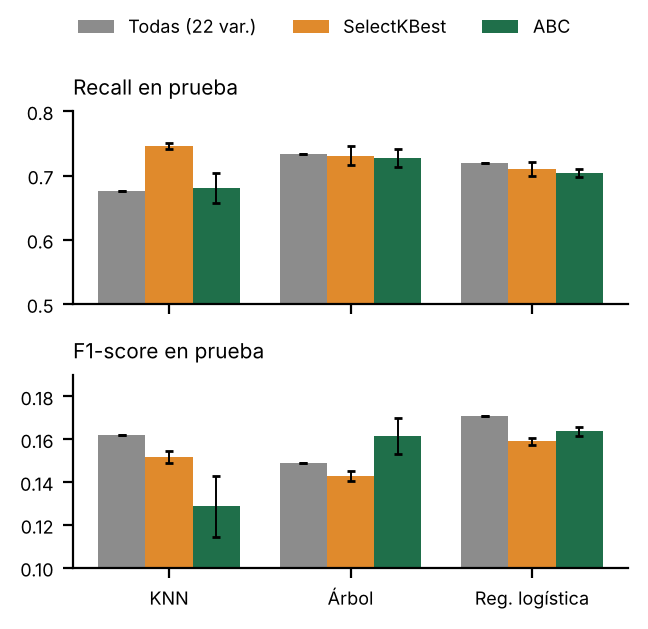

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(3.25, 3.1), sharex=True)
for ax, metrica, titulo in zip(axs, ['test_recall', 'test_f1'], ['Recall en prueba', 'F1-score en prueba']):
    for j, condicion in enumerate(['Todas', 'SelectKBest', 'ABC']):
        medias, desviaciones = [], []
        for clasificador in CLASIFICADORES:
            valores = res[(res['condicion'] == condicion) & (res['clasificador'] == clasificador)][metrica]
            medias.append(valores.mean())
            desviaciones.append(valores.std() if len(valores) > 1 else 0)
        etiqueta = 'Todas (22 var.)' if condicion == 'Todas' else condicion
        ax.bar(np.arange(3) + (j - 1) * 0.26, medias, 0.26, yerr=desviaciones, capsize=1.5,
               color=COLORES[condicion], label=etiqueta, error_kw={'lw': 0.7})
    ax.set_title(titulo, loc='left')
    ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylim(0.5, 0.8)
axs[1].set_ylim(0.10, 0.19)
axs[1].set_xticks(range(3))
axs[1].set_xticklabels([NOMBRE_CLF[c] for c in CLASIFICADORES])
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, ncol=3, loc='upper center', frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(CARPETA_RESULTADOS + 'fig_informe_comparacion.png', dpi=300)
plt.show()

**Figura 2.** Número de semillas en que cada método eligió cada variable (solo las elegidas al menos una vez).

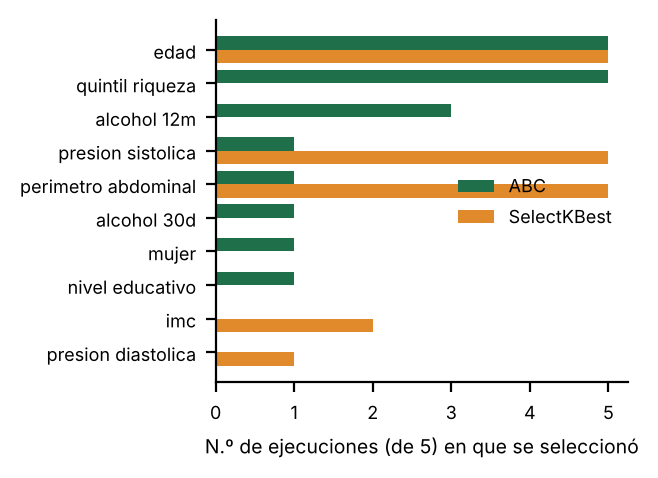

In [ ]:
fr = frecuencia[(frecuencia['frecuencia_abc'] > 0) | (frecuencia['frecuencia_skb'] > 0)]
fr = fr.sort_values(['frecuencia_abc', 'frecuencia_skb'])
n = len(SEMILLAS_ABC)
fig, ax = plt.subplots(figsize=(3.25, 2.4))
posiciones = np.arange(len(fr))
ax.barh(posiciones + 0.2, fr['frecuencia_abc'] * n, 0.4, color=COLORES['ABC'], label='ABC')
ax.barh(posiciones - 0.2, fr['frecuencia_skb'] * n, 0.4, color=COLORES['SelectKBest'], label='SelectKBest')
ax.set_yticks(posiciones)
ax.set_yticklabels(fr['variable'].str.replace('_', ' '))
ax.set_xticks(range(n + 1))
ax.set_xlabel('N.º de ejecuciones (de {}) en que se seleccionó'.format(n))
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='center right', frameon=False)
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS + 'fig_informe_frecuencia.png', dpi=300)
plt.show()

**Figura 3.** Convergencia de ABC en las 5 semillas.

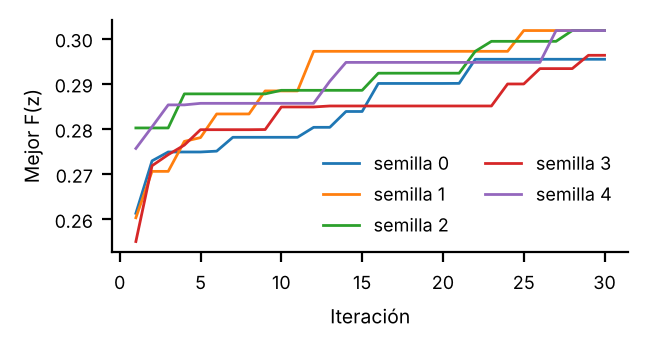

In [ ]:
fig, ax = plt.subplots(figsize=(3.25, 1.75))
for semilla in SEMILLAS_ABC:
    historial = abc[semilla]['historial']
    ax.plot(range(1, len(historial) + 1), historial, lw=1, label='semilla {}'.format(semilla))
ax.set_xlabel('Iteración')
ax.set_ylabel('Mejor F(z)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(ncol=2, frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS + 'fig_informe_convergencia.png', dpi=300)
plt.show()